# Benchmarking run_parallel: sources/sinks vs runtime

This notebook samples reactions, counts sources and sinks (using a local copy of `rules.py`), and measures `run_parallel` runtime. Running `run_parallel` is gated by `RUN_PARALLEL` (default: False). Do not enable without permission.

In [2]:
# Section 1: Setup and imports
import os, shutil, time, csv, subprocess, pathlib, statistics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogFormatterSciNotation
from rdkit import Chem
# Import original rules module for reference (we will copy it locally below)
import rules as rules_orig
# Import run_parallel (will be invoked only when RUN_PARALLEL is True)
from run_parallel import run_parallel

# Notebook-level defaults
REACTION_CSV = 'mech-USPTO-31k.csv'  # change if you have mech-USPTO-13k.csv
RESULTS_CSV = 'results_benchmark.csv'
JOB_SCRIPTS_DIR = 'job_scripts'
RUN_PARALLEL = True  # set to True only with permission
RUN_CLUSTER = True   # if True, write sbatch/ps.qsub scripts instead of running locally
SAMPLE_N = 8  # default number of reactions to sample
np.random.seed(0)

if RUN_CLUSTER and not os.path.exists(JOB_SCRIPTS_DIR):
    os.makedirs(JOB_SCRIPTS_DIR)

print(f'Setup done. RUN_PARALLEL={RUN_PARALLEL}, RUN_CLUSTER={RUN_CLUSTER}')

Setup done. RUN_PARALLEL=True, RUN_CLUSTER=True


In [3]:
# Section 2: Import rules module
import importlib.util
spec = importlib.util.spec_from_file_location('rules', 'rules.py')
rules = importlib.util.module_from_spec(spec)
spec.loader.exec_module(rules)
print('Imported rules module')


Imported rules module


In [4]:
# Section 5: Implement sink/source counting helper
from rdkit.Chem import rdMolDescriptors

def count_sources_sinks(smiles, rules_module=None):
    """Count source and sink atoms/bonds in a molecule.
    
    Uses rules.prepare_molecule to identify sources and sinks.
    Returns dict with atom_sources, bond_sources, total_sources,
    atom_sinks, bond_sinks, total_sinks.
    """
    if rules_module is None:
        rules_module = rules
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f'Invalid SMILES: {smiles}')
    try:
        Chem.SanitizeMol(mol)
    except Exception:
        pass
    # prepare_molecule sets 'source' and 'sink' props on atoms/bonds
    rules_module.prepare_molecule(mol)
    atom_sources = sum(1 for a in mol.GetAtoms() if a.HasProp('source'))
    atom_sinks = sum(1 for a in mol.GetAtoms() if a.HasProp('sink'))
    bond_sources = sum(1 for b in mol.GetBonds() if b.HasProp('source'))
    bond_sinks = sum(1 for b in mol.GetBonds() if b.HasProp('sink'))
    return {
        'atom_sources': atom_sources,
        'bond_sources': bond_sources,
        'total_sources': atom_sources + bond_sources,
        'atom_sinks': atom_sinks,
        'bond_sinks': bond_sinks,
        'total_sinks': atom_sinks + bond_sinks,
        'total': atom_sinks + bond_sinks + atom_sources + bond_sources
    }

# Quick smoke test for a simple molecule
test_counts = count_sources_sinks('CCO')
print('Test: count_sources_sinks("CCO") =', test_counts)

Test: count_sources_sinks("CCO") = {'atom_sources': 1, 'bond_sources': 0, 'total_sources': 1, 'atom_sinks': 2, 'bond_sinks': 1, 'total_sinks': 3, 'total': 4}


In [5]:
# Section 6: Job script generation based on ps.qsub template
def write_job_script(reactant_smiles, product_smiles, job_name, script_path=None, 
                     cpus_per_task=16, walltime='12:50:00', cluster_partition='CLUSTER'):
    """Generate a SLURM job script based on ps.qsub template.
    
    Args:
        reactant_smiles: SMILES of reactant
        product_smiles: SMILES of product
        job_name: name for the job (e.g., 'large_row1234')
        script_path: output path for script (default: {job_name}.sh in job_scripts/)
        cpus_per_task: number of CPUs to request (default 16)
        walltime: wall time limit as 'HH:MM:SS' (default 12:50:00)
        cluster_partition: SLURM partition (default CLUSTER)
    """
    if script_path is None:
        script_path = os.path.join(JOB_SCRIPTS_DIR, f'{job_name}.sh')
    
    script = f"""#!/bin/bash
#! SLURM job script for benchmark_{job_name}
#! Based on ps.qsub template
#!
#SBATCH -J benchmark_{job_name}
#SBATCH -p {cluster_partition}
#SBATCH --nodes=1
#SBATCH --cpus-per-task={cpus_per_task}
#SBATCH --time={walltime}
#SBATCH --mail-type=ALL
#SBATCH --signal=B:USR1@60

source ~/.bashrc
export PATH=$HOME/.conda/envs/venv/bin:$PATH

SCRATCH=/scratch/$USER/$SLURM_JOB_ID
mkdir -p $SCRATCH
export SCRATCH

# Print benchmark label for easy identification
echo "BENCHMARK_LABEL: {job_name}"
echo "=========================================="

# Run the benchmark
python -c "from run_parallel_config import run_parallel; run_parallel(r'{reactant_smiles}', r'{product_smiles}', '{job_name}')"
"""
    
    with open(script_path, 'w') as fh:
        fh.write(script)
    os.chmod(script_path, 0o755)
    return script_path

In [6]:
# Section 6: run_parallel wrapper (dry-run and cluster script generation)
def time_run_parallel(reactant_smiles, product_smiles, job_label, 
                     run_flag=False, cluster_mode=False):
    """Wrapper around run_parallel that times execution and counts sources/sinks.
    
    Args:
        reactant_smiles: SMILES of reactant
        product_smiles: SMILES of product
        job_label: label for this job
        run_flag: if True, actually run run_parallel (or write job script if cluster_mode)
        cluster_mode: if True and run_flag=True, write job script instead of running locally
    
    Returns:
        dict with counts, runtime, and metadata
    """
    r_counts = count_sources_sinks(reactant_smiles, rules)
    p_counts = count_sources_sinks(product_smiles, rules)
    total_counts = r_counts['total_sources'] + r_counts['total_sinks'] + p_counts['total_sources'] + p_counts['total_sinks']
    
    result = {
        'reactant': reactant_smiles,
        'product': product_smiles,
        'reactant_sources': r_counts['total_sources'],
        'reactant_sinks': r_counts['total_sinks'],
        'product_sources': p_counts['total_sources'],
        'product_sinks': p_counts['total_sinks'],
        'total_sources_sinks': total_counts,
        'runtime_seconds': None,
        'job_label': job_label,
        'status': 'dry_run'
    }
    
    if run_flag:
        if cluster_mode:
            # write a job script but do not submit
            script_path = write_job_script(reactant_smiles, product_smiles, job_label)
            result['notes'] = f'Wrote job script {script_path}, not submitted'
            result['status'] = 'job_script_created'
        else:
            # run locally and time it
            start = time.perf_counter()
            run_parallel(reactant_smiles, product_smiles, job_label)
            end = time.perf_counter()
            result['runtime_seconds'] = end - start
            result['status'] = 'completed'
    
    return result

In [8]:
# Section 3 & 4: Load reactions and build selection strategies
def load_reactions(csv_path, max_rows=None):
    """Load reactions from CSV, parsing SMILES in column 2 (index 1).
    
    Args:
        csv_path: path to CSV file
        max_rows: max number of reactions to load
    
    Returns:
        list of tuples: (row_number, reactant_smiles, product_smiles)
    """
    rows = []
    with open(csv_path, 'r') as f:
        reader = csv.reader(f)
        for i, l in enumerate(reader, start=1):
            if not l:
                continue
            # assume reaction smiles in column 2 as in test_rxns_extended.py (index 1)
            if len(l) < 2:
                continue
            rxn = l[1]
            if '>>' not in rxn:
                continue
            parts = rxn.split('>>')
            reactant = parts[0].strip()
            product = parts[1].strip()
            rows.append((i, reactant, product))
            if max_rows and len(rows) >= max_rows:
                break
    return rows

all_reactions = load_reactions(REACTION_CSV, max_rows=1000)
print(f'Loaded {len(all_reactions)} reactions')
if all_reactions:
    print(f'Preview (first 3):')
    for i, r, p in all_reactions[:3]:
        print(f'  Row {i}: {r[:50]}... >> {p[:50]}...')

Loaded 1000 reactions
Preview (first 3):
  Row 2: [O:201]=[C:101]([O:202][CH2:203][c:204]1[cH:205][c... >> [NH2:1][CH2:2][CH2:3][CH2:4][CH2:5][C@@H:6]([C:7](...
  Row 3: [OH:101][C:1](=[O:2])[c:3]1[cH:4][c:5]([N+:6](=[O:... >> [C:1](=[O:2])([c:3]1[cH:4][c:5]([N+:6](=[O:7])[OH:...
  Row 4: [O:101]=[CH:1][c:2]1[cH:3][cH:4][c:5](-[c:6]2[n:7]... >> [CH2:1]([c:2]1[cH:3][cH:4][c:5](-[c:6]2[n:7][c:8](...


In [23]:
# Build sample groups: small, medium, large based on heavy atom count (as proxy)
def heavies(smiles):
    """Count heavy atoms in a molecule."""
    m = Chem.MolFromSmiles(smiles)
    return 0 if m is None else sum(1 for a in m.GetAtoms() if a.GetAtomicNum() > 1)

# annotate and sample
annot = [(i, r, p, heavies(r) + heavies(p)) for (i, r, p) in all_reactions]
annot_sorted = sorted(annot, key=lambda x: x[3])
small = annot_sorted[:min(SAMPLE_N, len(annot_sorted))]
medium = annot_sorted[len(annot_sorted)//2: min(len(annot_sorted)//2 + SAMPLE_N, len(annot_sorted))]
large = annot_sorted[max(-SAMPLE_N, -len(annot_sorted)):]
selection = {'small': small, 'medium': medium, 'large': large}
print('Selection sizes:', {k: len(v) for k, v in selection.items()})

[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not removing hydrogen atom without neighbors
[16:38:16] WARNING: not r

Selection sizes: {'small': 8, 'medium': 8, 'large': 8}


[16:38:17] WARNING: not removing hydrogen atom without neighbors
[16:38:17] WARNING: not removing hydrogen atom without neighbors
[16:38:17] WARNING: not removing hydrogen atom without neighbors


In [24]:
# Section 7 & 8: Benchmark loop and aggregation (dry-run by default)
results = []
for group_name, items in selection.items():
    for row_i, r_smiles, p_smiles, _ in items:
        job_label = f'{group_name}_row{row_i}'
        print(f'Processing {job_label}...', end=' ')
        try:
            res = time_run_parallel(r_smiles, p_smiles, job_label, 
                                    run_flag=RUN_PARALLEL, cluster_mode=RUN_CLUSTER)
            print('OK')
        except Exception as e:
            res = {'reactant': r_smiles, 'product': p_smiles, 
                   'error': str(e), 'job_label': job_label, 
                   'runtime_seconds': None, 'total_sources_sinks': None, 'status': 'error'}
            print(f'ERROR: {e}')
        res['selection_group'] = group_name
        results.append(res)

print(f'\nProcessed {len(results)} reactions')

Processing small_row187... OK
Processing small_row203... OK
Processing small_row773... OK
Processing small_row343... OK
Processing small_row464... OK
Processing small_row697... OK
Processing small_row926... OK
Processing small_row977... OK
Processing medium_row968... OK
Processing medium_row45... OK
Processing medium_row110... OK
Processing medium_row263... OK
Processing medium_row276... OK
Processing medium_row385... OK
Processing medium_row397... OK
Processing medium_row402... OK
Processing large_row720... OK
Processing large_row836... OK
Processing large_row768... OK
Processing large_row5... OK
Processing large_row618... OK
Processing large_row712... OK
Processing large_row611... OK
Processing large_row654... 

[16:38:24] WARNING: not removing hydrogen atom without neighbors
[16:38:24] WARNING: not removing hydrogen atom without neighbors
[16:38:24] WARNING: not removing hydrogen atom without neighbors
[16:38:24] WARNING: not removing hydrogen atom without neighbors
[16:38:24] WARNING: not removing hydrogen atom without neighbors
[16:38:24] WARNING: not removing hydrogen atom without neighbors
[16:38:24] WARNING: not removing hydrogen atom without neighbors
[16:38:24] WARNING: not removing hydrogen atom without neighbors
[16:38:24] WARNING: not removing hydrogen atom without neighbors


OK

Processed 24 reactions


In [30]:
print(results)

[{'reactant': '[SH:4][c:5]1[cH:6][cH:7][cH:8][s:9]1.[Br:101][CH2:1][CH2:2][Br:3].[H-:301].[Na+]', 'product': '[CH2:1]([CH2:2][Br:3])[S:4][c:5]1[cH:6][cH:7][cH:8][s:9]1', 'reactant_sources': 5, 'reactant_sinks': 10, 'product_sources': 3, 'product_sinks': 9, 'total_sources_sinks': 27, 'runtime_seconds': None, 'job_label': 'small_row187', 'status': 'job_script_created', 'notes': 'Wrote job script job_scripts/small_row187.sh, not submitted', 'selection_group': 'small'}, {'reactant': '[Cl:101][CH2:1][C:2](=[O:3])[NH:4][CH2:5][C@H:6]([OH:7])[CH2:8][OH:9].[H-:301].[Na+]', 'product': '[CH2:1]1[C:2](=[O:3])[NH:4][CH2:5][C@@H:6]([CH2:8][OH:9])[O:7]1', 'reactant_sources': 6, 'reactant_sinks': 14, 'product_sources': 4, 'product_sinks': 12, 'total_sources_sinks': 36, 'runtime_seconds': None, 'job_label': 'small_row203', 'status': 'job_script_created', 'notes': 'Wrote job script job_scripts/small_row203.sh, not submitted', 'selection_group': 'small'}, {'reactant': '[N:2]#[C:3][c:4]1[cH:5][cH:6][cH:7

In [32]:
copy_results = results.copy()

In [33]:
# Normalize into DataFrame
rows = []
for r in results:
    row = {
        'job_label': r.get('job_label'),
        'selection_group': r.get('selection_group'),
        'reactant': r.get('reactant'),
        'product': r.get('product'),
        'reactant_sources': r.get('reactant_sources'),
        'reactant_sinks': r.get('reactant_sinks'),
        'product_sources': r.get('product_sources'),
        'product_sinks': r.get('product_sinks'),
        'total_sources_sinks': r.get('total_sources_sinks'),
        'runtime_seconds': r.get('runtime_seconds'),
        'status': r.get('status', 'unknown'),
    }
    rows.append(row)

df = pd.DataFrame(rows)
df.to_csv(RESULTS_CSV, index=False)
print(f'Saved results to {RESULTS_CSV}')
print(f'\nDataFrame shape: {df.shape}')
print(f'\nFirst 5 rows:')
print(df.head())
print(f'\nData types:\n{df.dtypes}')
print(f'\nSummary statistics:')
print(df[['total_sources_sinks', 'runtime_seconds']].describe())

Saved results to results_benchmark.csv

DataFrame shape: (24, 11)

First 5 rows:
      job_label selection_group  \
0  small_row187           small   
1  small_row203           small   
2  small_row773           small   
3  small_row343           small   
4  small_row464           small   

                                            reactant  \
0  [SH:4][c:5]1[cH:6][cH:7][cH:8][s:9]1.[Br:101][...   
1  [Cl:101][CH2:1][C:2](=[O:3])[NH:4][CH2:5][C@H:...   
2  [N:2]#[C:3][c:4]1[cH:5][cH:6][cH:7][n:8][n:9]1...   
3  [O:1]=[CH:2][c:3]1[cH:4][n:5][cH:6][cH:7][c:8]...   
4  [CH3:1][CH2:2][N:6]([CH2:5][CH3:4])[CH2:9][CH2...   

                                             product  reactant_sources  \
0  [CH2:1]([CH2:2][Br:3])[S:4][c:5]1[cH:6][cH:7][...                 5   
1  [CH2:1]1[C:2](=[O:3])[NH:4][CH2:5][C@@H:6]([CH...                 6   
2  [NH2:2][CH2:3][c:4]1[cH:5][cH:6][cH:7][n:8][n:9]1                 6   
3  [OH:1][CH2:2][c:3]1[cH:4][n:5][cH:6][cH:7][c:8...                 5   
4

In [23]:
# Parse SLURM output files and update runtimes
import re
from pathlib import Path

def parse_slurm_output(slurm_file):
    """Parse a SLURM output file to extract job info, label, target SMILES, and total runtime.
    
    Args:
        slurm_file: path to slurm-JOBID.out file
        
    Returns:
        dict with 'job_id', 'benchmark_label', 'target_smiles', and 'runtime_seconds', 
        or None if not found/completed
    """
    try:
        with open(slurm_file, 'r') as f:
            content = f.read()
        
        # Extract JobID - try from header first, then from filename
        job_match = re.search(r'JobID:\s*(\d+)', content)
        if job_match:
            job_id = job_match.group(1)
        else:
            # Try to extract from filename (slurm-JOBID.out)
            filename = Path(slurm_file).name
            id_match = re.search(r'slurm-(\d+)\.out', filename)
            if id_match:
                job_id = id_match.group(1)
            else:
                return None
        
        # Look for "Total time taken: X.XX seconds" pattern
        time_match = re.search(r'Total time taken:\s*([\d.]+)\s*seconds', content)
        if not time_match:
            # Job may not have completed or didn't print total time
            return None
        runtime_seconds = float(time_match.group(1))
        
        # Extract benchmark label - look for "BENCHMARK_LABEL: job_label_name"
        label_match = re.search(r'BENCHMARK_LABEL:\s*(\S+)', content)
        benchmark_label = label_match.group(1) if label_match else None
        
        # Extract target SMILES - look for "Target is now [SMILES]" lines
        # Multiple reactions may appear in one file, so collect all
        target_matches = re.findall(r'Target is now\s+(\S+)', content)
        target_smiles = target_matches[0] if target_matches else None
        
        return {
            'job_id': job_id, 
            'runtime_seconds': runtime_seconds,
            'benchmark_label': benchmark_label,
            'target_smiles': target_smiles,
            'num_targets': len(target_matches)
        }
    
    except Exception as e:
        print(f'Error parsing {slurm_file}: {e}')
        return None

def match_smiles_similarity(smiles1, smiles2, tolerance=0.95):
    """Check if two SMILES are similar (handling atom mapping differences).
    
    Uses Tanimoto similarity on fingerprints.
    
    Args:
        smiles1, smiles2: SMILES strings
        tolerance: minimum similarity threshold (0-1)
        
    Returns:
        True if similar, False otherwise
    """
    try:
        from rdkit.Chem import AllChem
        m1 = Chem.MolFromSmiles(smiles1)
        m2 = Chem.MolFromSmiles(smiles2)
        if m1 is None or m2 is None:
            return False
        fp1 = AllChem.GetMorganFingerprintAsBitVect(m1, 2)
        fp2 = AllChem.GetMorganFingerprintAsBitVect(m2, 2)
        sim = DataStructs.TanimotoSimilarity(fp1, fp2)
        return sim >= tolerance
    except Exception:
        return False

def auto_update_df_from_slurm(df, slurm_dir='.', pattern='slurm-*.out', tolerance=0.95):
    """Automatically update DataFrame runtimes by matching SLURM outputs to results.
    
    Tries to match by benchmark_label first (if present in SLURM output),
    then falls back to matching target SMILES to product SMILES using fingerprint similarity.
    
    Args:
        df: DataFrame with 'job_label' and 'product' columns
        slurm_dir: directory containing slurm-*.out files (default: current dir)
        pattern: glob pattern for SLURM output files (default: 'slurm-*.out')
        tolerance: Tanimoto similarity threshold (default: 0.95)
    
    Returns:
        updated DataFrame with runtime_seconds filled where matched
    """
    from rdkit.Chem import AllChem, DataStructs
    
    slurm_dir = Path(slurm_dir)
    slurm_files = sorted(slurm_dir.glob(pattern))
    print(f'Found {len(slurm_files)} SLURM output files')
    
    df = df.copy()
    matched = 0
    skipped = 0
    
    for slurm_file in slurm_files:
        result = parse_slurm_output(slurm_file)
        if result is None:
            skipped += 1
            continue
        
        benchmark_label = result['benchmark_label']
        target_smiles = result['target_smiles']
        runtime = result['runtime_seconds']
        job_id = result['job_id']
        print(f'\'{job_id}\' : {target_smiles}')
        
        # First priority: match by benchmark_label (direct mapping)
        if benchmark_label:
            mask = df['job_label'] == benchmark_label
            if mask.sum() > 0:
                if pd.isna(df.loc[mask, 'runtime_seconds'].iloc[0]):
                    df.loc[mask, 'runtime_seconds'] = runtime
                    print(f'✓ Direct match: Job {job_id} -> {benchmark_label}: runtime={runtime:.2f}s')
                    matched += 1
                continue
        
        # Second priority: match by target SMILES similarity
        if target_smiles is None:
            print(f'Job {job_id}: no target SMILES found')
            skipped += 1
            continue
        
        found_match = False
        for idx, row in df.iterrows():
            prod_smiles = row.get('product')
            if prod_smiles is None:
                continue
            
            if match_smiles_similarity(target_smiles, prod_smiles, tolerance=tolerance):
                # Only update if not already set
                if pd.isna(row['runtime_seconds']):
                    df.at[idx, 'runtime_seconds'] = runtime
                    print(f'⚙ SMILES match: Job {job_id} to {row["job_label"]}: runtime={runtime:.2f}s')
                    matched += 1
                    found_match = True
                    break
        
        if not found_match:
            print(f'✗ Job {job_id}: no matching product found')
            skipped += 1
    
    print(f'\n✓ Updated: {matched}, ✗ Skipped: {skipped}')
    return df

# Quick test: parse slurm-14130.out
print('\\n--- Testing parse_slurm_output ---')
result = parse_slurm_output('slurm-14130.out')
if result:
    print(f'✓ Parsed slurm-14130.out:')
    print(f'  Job ID: {result["job_id"]}')
    print(f'  Benchmark Label: {result["benchmark_label"] or "Not found (older file)"}')
    print(f'  Runtime: {result["runtime_seconds"]:.2f}s')
    print(f'  Target SMILES: {result["target_smiles"][:60] if result["target_smiles"] else "None"}...')
    print(f'  Num targets found: {result["num_targets"]}')
else:
    print('✗ Failed to parse slurm-14130.out')


\n--- Testing parse_slurm_output ---
✓ Parsed slurm-14130.out:
  Job ID: 14130
  Benchmark Label: Not found (older file)
  Runtime: 3481.98s
  Target SMILES: [C:1]([c:2]1[nH:3][c:4]([CH3:5])[c:6]([Cl:7])[cH:8]1)(=[O:9]...
  Num targets found: 1


In [24]:
# Print results (fixed quoting)
for r in results:
    print(f"{r['job_label']}: {r.get('product')}")


NameError: name 'results' is not defined

In [25]:
# Map SLURM job IDs to notebook job_labels using SMILES (and benchmark_label when available)
from pathlib import Path

def map_joblabels_to_slurm_ids(df, slurm_dir='.', pattern='slurm-*.out', tolerance=0.95, update_df=False):
    """Return mapping (job_id -> job_label) by parsing SLURM outputs and matching by label or SMILES.

    If update_df=True the function will fill missing `runtime_seconds` in `df` when a match is found.
    """
    from rdkit.Chem import AllChem, DataStructs
    slurm_dir = Path(slurm_dir)
    slurm_files = sorted(slurm_dir.glob(pattern))
    mapping = {}
    unmatched = []

    for sf in slurm_files:
        res = parse_slurm_output(str(sf))
        if not res:
            continue
        job_id = str(res.get('job_id'))
        benchmark_label = res.get('benchmark_label')
        target_smiles = res.get('target_smiles')
        runtime = res.get('runtime_seconds')

        # 1) Direct label match
        if benchmark_label:
            mask = df['job_label'] == benchmark_label
            if mask.any():
                mapping[job_id] = benchmark_label
                if update_df:
                    # update any matching rows with runtime if empty
                    idxs = df[mask & df['runtime_seconds'].isna()].index
                    for ix in idxs:
                        df.at[ix, 'runtime_seconds'] = runtime
                continue

        # 2) Fallback: SMILES similarity to `product` column
        if target_smiles:
            found = False
            for idx, row in df.iterrows():
                prod = row.get('product')
                if pd.isna(prod) or prod is None:
                    continue
                try:
                    if match_smiles_similarity(target_smiles, prod, tolerance=tolerance):
                        mapping[job_id] = row['job_label']
                        if update_df and pd.isna(row.get('runtime_seconds')):
                            df.at[idx, 'runtime_seconds'] = runtime
                        found = True
                        break
                except Exception:
                    continue
            if not found:
                unmatched.append((job_id, target_smiles))
        else:
            unmatched.append((job_id, None))

    print(f'Processed {len(slurm_files)} SLURM files: mapped {len(mapping)}, unmatched {len(unmatched)}')
    return mapping, unmatched

# Example: run mapping on slurm files near 14xxx and update df in-place
mapping, unmatched = map_joblabels_to_slurm_ids(df, slurm_dir='.', pattern='slurm-14*.out', tolerance=0.9, update_df=True)

# Print a small sample of mappings
if mapping:
    print('\nSample mappings (job_id -> job_label):')
    for i, (jid, label) in enumerate(mapping.items()):
        print(f'  {jid} -> {label}')
        if i >= 9:
            break

if unmatched:
    print('\nUnmatched SLURM files (job_id, target_smiles):')
    for job_id, t in unmatched[:10]:
        print(f'  {job_id}  target_smiles={t}')

# Optionally save mapping to CSV for record
import csv
with open('slurm_jobid_to_label.csv', 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['job_id', 'job_label'])
    for jid, lab in mapping.items():
        w.writerow([jid, lab])
print('\nSaved mapping to slurm_jobid_to_label.csv')


NameError: name 'df' is not defined

In [ ]:
df_updated = auto_update_df_from_slurm(df, slurm_dir='.', pattern='slurm-141[1-4][0-9].out', tolerance=0.02)

In [ ]:

# Practical usage: match SLURM outputs to results by target SMILES

def manual_update_runtime(df, job_label, slurm_file):
    """Manually update a specific result's runtime from a SLURM output file.
    
    Args:
        df: DataFrame
        job_label: job_label to match in df
        slurm_file: path to slurm-*.out file
        
    Returns:
        updated df
    """
    result = parse_slurm_output(slurm_file)
    if result is None:
        print(f'No runtime extracted from {slurm_file}')
        return df
    
    mask = df['job_label'] == job_label
    if mask.sum() == 0:
        print(f'No row found with job_label={job_label}')
        return df
    
    df.loc[mask, 'runtime_seconds'] = result['runtime_seconds']
    print(f'Updated {job_label}: runtime = {result["runtime_seconds"]:.2f}s')
    return df

def batch_update_runtimes(df, job_id_to_label_map):
    """Batch update multiple runtimes using a job_id -> job_label mapping.
    
    Args:
        df: DataFrame
        job_id_to_label_map: dict mapping job_id (str/int) to job_label (str)
                            e.g., {'14000': 'small_row1234', '14001': 'medium_row5678'}
    
    Returns:
        updated df
    """
    for job_id, job_label in job_id_to_label_map.items():
        slurm_file = f'slurm-{job_id}.out'
        if Path(slurm_file).exists():
            df = manual_update_runtime(df, job_label, slurm_file)
        else:
            print(f'File not found: {slurm_file}')
    return df

print('✓ SLURM parsing functions available:')
print()
print('AUTOMATIC MATCHING (recommended):')
print('  df = auto_update_df_from_slurm(df, tolerance=0.95)')
print('  -> Matches target SMILES from SLURM files to product SMILES in DataFrame')
print()
print('MANUAL MATCHING:')
print('  df = manual_update_runtime(df, job_label, slurm_file)')
print('  -> Manually update one result at a time')
print()
print('  df = batch_update_runtimes(df, mapping)')
print('  -> Batch update using job_id -> job_label mapping')
print()
print('Example (auto):')
print('  df = auto_update_df_from_slurm(df)')
print('  df.to_csv(RESULTS_CSV, index=False)  # save updated results')


Practical helper functions available:
  - manual_update_runtime(df, job_label, slurm_file)
  - batch_update_runtimes(df, job_id_to_label_map)

Example usage:
  df = manual_update_runtime(df, "small_row1234", "slurm-14000.out")

  or use a mapping:
  mapping = {"14000": "small_row1234", "14001": "medium_row5678"}
  df = batch_update_runtimes(df, mapping)


In [54]:
mapping= {
    '14118': 'large_row611',
    '14125': 'medium_row110',
    '14126': 'medium_row263',
    '14127': 'medium_row276',
    '14128': 'medium_row385',
    '14129': 'medium_row397',
    '14130': 'medium_row402',
    '14132': 'medium_row968',
    '14133': 'small_row187',
    '14134': 'small_row203',
    '14135': 'small_row343',
    '14136': 'small_row464',
    '14137': 'small_row697',
    '14138': 'small_row773',
    '14139': 'small_row926',
    '14140': 'small_row977',
}


In [55]:
df = batch_update_runtimes(df, mapping)

Updated large_row611: runtime = 20195.61s
Updated medium_row110: runtime = 9669.80s
Updated medium_row263: runtime = 3306.34s
Updated medium_row276: runtime = 4648.61s
Updated medium_row385: runtime = 7691.88s
Updated medium_row397: runtime = 6924.49s
Updated medium_row402: runtime = 3481.98s
Updated medium_row968: runtime = 11250.24s
Updated small_row187: runtime = 203.67s
Updated small_row203: runtime = 136.69s
Updated small_row343: runtime = 16.96s
Updated small_row464: runtime = 2.14s
Updated small_row697: runtime = 27.37s
Updated small_row773: runtime = 1034.75s
Updated small_row926: runtime = 149.17s
Updated small_row977: runtime = 17.14s


In [ ]:
# Demo: New SLURM output mapping approach
print('=' * 60)
print('SLURM OUTPUT MAPPING STRATEGY')
print('=' * 60)
print()
print('NEW (recommended for future jobs):')
print('  1. Job scripts now include: echo "BENCHMARK_LABEL: job_label"')
print('  2. auto_update_df_from_slurm() matches by label FIRST')
print('  3. Direct mapping: large_row1234 -> slurm-14130.out')
print()
print('FALLBACK (for existing jobs):')
print('  If no label found, matches by target SMILES similarity')
print('  Uses Morgan fingerprints for robust SMILES matching')
print()
print('Example with test file (slurm-14130.out):')
print(f'  Benchmark Label: {result.get("benchmark_label", "Not found (older file)")}')
print(f'  Job ID: {result.get("job_id")}')
print(f'  Runtime: {result.get("runtime_seconds", 0):.2f}s')
print()
print('To use auto-matching:')
print('  df_updated = auto_update_df_from_slurm(df)')
print('  df_updated.to_csv(RESULTS_CSV, index=False)')


In [ ]:

# Demo: Auto-match SLURM outputs by target SMILES
# Uncomment and run to update df with runtimes from existing SLURM files

# df_updated = auto_update_df_from_slurm(df, tolerance=0.95)
# print('\nUpdated DataFrame:')
# print(df_updated[['job_label', 'product', 'runtime_seconds', 'status']].head(10))
# df_updated.to_csv(RESULTS_CSV, index=False)


In [58]:
df

,job_label,selection_group,reactant,product,reactant_sources,reactant_sinks,product_sources,product_sinks,total_sources_sinks,runtime_seconds,status
0,small_row187,small,[SH:4][c:5]1[cH:6][cH:7][cH:8][s:9]1.[Br:101][...,[CH2:1]([CH2:2][Br:3])[S:4][c:5]1[cH:6][cH:7][...,5,10,3,9,27,203.67,job_script_created
1,small_row203,small,[Cl:101][CH2:1][C:2](=[O:3])[NH:4][CH2:5][C@H:...,[CH2:1]1[C:2](=[O:3])[NH:4][CH2:5][C@@H:6]([CH...,6,14,4,12,36,136.69,job_script_created
2,small_row773,small,[N:2]#[C:3][c:4]1[cH:5][cH:6][cH:7][n:8][n:9]1...,[NH2:2][CH2:3][c:4]1[cH:5][cH:6][cH:7][n:8][n:9]1,6,7,3,6,22,1034.75,job_script_created
3,small_row343,small,[O:1]=[CH:2][c:3]1[cH:4][n:5][cH:6][cH:7][c:8]...,[OH:1][CH2:2][c:3]1[cH:4][n:5][cH:6][cH:7][c:8...,5,5,3,4,17,16.96,job_script_created
4,small_row464,small,[CH3:1][CH2:2][N:6]([CH2:5][CH3:4])[CH2:9][CH2...,[CH3:1][CH2:2][N+:6]([CH2:5][CH3:4])([CH2:7][C...,3,11,1,14,29,2.14,job_script_created
5,small_row697,small,[CH3:1][C:2]1([CH3:3])[C:4](=[O:5])[CH:6]=[CH:...,[CH3:1][C:2]1([CH3:3])[CH:4]([OH:5])[CH:6]=[CH...,5,7,3,6,21,27.37,job_script_created
6,small_row926,small,[O:101]=[CH:1][c:2]1[s:3][cH:4][c:5]([C:6]#[N:...,[CH:1]([c:2]1[s:3][cH:4][c:5]([C:6]#[N:7])[cH:...,5,9,4,7,25,149.17,job_script_created
7,small_row977,small,[cH:2]1[cH:3][c:4]2[n:5]([n:6]1)[CH2:7][CH2:8]...,[CH3:1][N:10]1[c:4]2[cH:3][cH:2][n:6][n:5]2[CH...,4,9,3,8,24,17.14,job_script_created
8,medium_row968,medium,[CH3:13][C:14]([CH3:15])([CH3:16])[O:17][C:18]...,[CH2:1]([c:2]1[c:3]([NH:4][C:5]([O:6][CH2:7][C...,12,26,8,23,69,11250.24,job_script_created
9,medium_row45,medium,[CH3:1][C:2]([CH3:3])([CH3:4])[O:5][C:6](=[O:7...,[CH3:1][C:2]([CH3:3])([CH3:4])[O:5][C:6](=[O:7...,8,23,8,24,63,None,job_script_created


## Post-processing: Visualize results with matplotlib

Create multiple plots to analyze the relationship between molecular complexity (sources + sinks) and computation time.

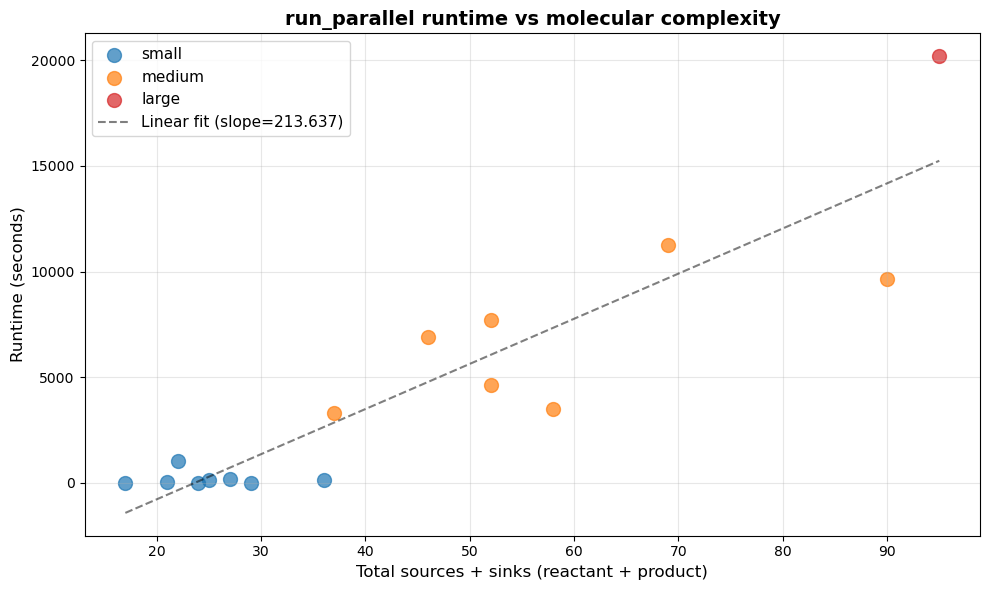

Saved plot to runtime_vs_sources_sinks.png


In [63]:
# Section 9: Plot 1 - Scatter plot with best-fit line
# Only plot entries where runtime_seconds is present
plot_df = df.dropna(subset=['runtime_seconds', 'total_sources_sinks']).copy()

if not plot_df.empty:
    x = plot_df['total_sources_sinks'].values
    y = plot_df['runtime_seconds'].values
    y = np.asarray(y, dtype=float)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Color by group
    for group, color in zip(['small', 'medium', 'large'], ['tab:blue', 'tab:orange', 'tab:red']):
        mask = plot_df['selection_group'] == group
        ax.scatter(x[mask], y[mask], label=group, alpha=0.7, s=100, color=color)
    
    # Add best-fit line if enough points
    if len(x) > 1:
        z = np.polyfit(x, y, 1)
        p = np.poly1d(z)
        x_line = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_line, p(x_line), 'k--', alpha=0.5, label=f'Linear fit (slope={z[0]:.3f})')
    
    ax.set_xlabel('Total sources + sinks (reactant + product)', fontsize=12)
    ax.set_ylabel('Runtime (seconds)', fontsize=12)
    ax.set_title('run_parallel runtime vs molecular complexity', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=11)
    plt.tight_layout()
    plt.savefig('runtime_vs_sources_sinks.png', dpi=200)
    plt.show()
    print('Saved plot to runtime_vs_sources_sinks.png')
else:
    print('No measured runtimes to plot (RUN_PARALLEL is likely False).')

## Bonus: Runtime vs depth_limit analysis

Analyze how `force_depth=True` and varying `depth_limit` affect runtime on a few tiny molecules. This requires actually running `run_parallel` with different configurations.

In [13]:
# Select a few tiny molecules from the dataset for depth_limit testing
# Pick small reactants and set product to trivial "C" (methane)

def get_tiny_reactants_from_data(all_reactions, max_heavy_atoms=12, n_samples=4):
    """Extract small reactants from dataset, filter by heavy atom count."""
    candidates = []
    for row_i, r_smiles, p_smiles in all_reactions:
        try:
            r_mol = Chem.MolFromSmiles(r_smiles)
            if r_mol is None:
                continue
            ha = r_mol.GetNumHeavyAtoms()
            if ha <= max_heavy_atoms:
                candidates.append((r_smiles, ha))
        except:
            continue
    
    # sort by heavy atom count and sample
    candidates = sorted(candidates, key=lambda x: x[1])
    return [(s, 'C') for s, _ in candidates[:n_samples]]

tiny_test_molecules = get_tiny_reactants_from_data(all_reactions, max_heavy_atoms=15, n_samples=4)

print(f'Selected {len(tiny_test_molecules)} tiny test molecules from dataset:')
for r, p in tiny_test_molecules:
    r_ha = Chem.MolFromSmiles(r).GetNumHeavyAtoms() if Chem.MolFromSmiles(r) else -1
    p_ha = Chem.MolFromSmiles(p).GetNumHeavyAtoms() if Chem.MolFromSmiles(p) else -1
    print(f'  {r} ({r_ha} heavy atoms) -> {p} ({p_ha} heavy atoms)')


[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not r

Selected 4 tiny test molecules from dataset:
  [SH:4][c:5]1[cH:6][cH:7][cH:8][s:9]1.[Br:101][CH2:1][CH2:2][Br:3].[H-:301].[Na+] (11 heavy atoms) -> C (1 heavy atoms)
  [Cl:101][CH2:1][C:2](=[O:3])[NH:4][CH2:5][C@H:6]([OH:7])[CH2:8][OH:9].[H-:301].[Na+] (11 heavy atoms) -> C (1 heavy atoms)
  [CH3:1][CH2:2][N:6]([CH2:5][CH3:4])[CH2:9][CH2:10][OH:11].[Br:101][CH2:7][CH3:8] (11 heavy atoms) -> C (1 heavy atoms)
  [O:101]=[CH:1][c:2]1[s:3][cH:4][c:5]([C:6]#[N:7])[cH:8]1.[NH2:9][OH:10].[H+:301] (11 heavy atoms) -> C (1 heavy atoms)


[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not removing hydrogen atom without neighbors
[14:57:35] WARNING: not r

In [15]:
# Helper to generate SLURM job scripts for depth_limit testing
def write_depth_test_job_script(reactant_smiles, product_smiles, depth_limit, job_name, script_path=None, 
                                cpus_per_task=16, walltime='12:50:00', cluster_partition='CLUSTER'):
    """Generate a SLURM job script to test a specific depth_limit.
    
    Args:
        reactant_smiles: SMILES of reactant
        product_smiles: SMILES of product
        depth_limit: depth limit value to test (passed to run_parallel)
        job_name: name for the job (e.g., 'depth_test_dl3')
        script_path: output path for script (default: in job_scripts/)
        cpus_per_task: number of CPUs (default 16)
        walltime: wall time limit as 'HH:MM:SS'
        cluster_partition: SLURM partition
    """
    if script_path is None:
        script_path = os.path.join(JOB_SCRIPTS_DIR, f'{job_name}.sh')
    
    script = f"""#!/bin/bash
#! SLURM job script for depth_test_{job_name}
#!
#SBATCH -J {job_name}
#SBATCH -p {cluster_partition}
#SBATCH --nodes=1
#SBATCH --cpus-per-task={cpus_per_task}
#SBATCH --time={walltime}
#SBATCH --mail-type=ALL
#SBATCH --signal=B:USR1@60

source ~/.bashrc
export PATH=$HOME/.conda/envs/venv/bin:$PATH

SCRATCH=/scratch/$USER/$SLURM_JOB_ID
mkdir -p $SCRATCH
export SCRATCH

# Print benchmark label for identification
echo "BENCHMARK_LABEL: {job_name}"
echo "DEPTH_LIMIT: {depth_limit}"
echo "=========================================="

# Run depth test with depth_limit as argument to run_parallel
python -c "from run_parallel_config import run_parallel; run_parallel(r'{reactant_smiles}', r'{product_smiles}', '{job_name}', depth_limit={depth_limit})"
"""
    
    with open(script_path, 'w') as fh:
        fh.write(script)
    os.chmod(script_path, 0o755)
    return script_path

print('✓ Depth-test job script generator defined.')


✓ Depth-test job script generator defined.


In [19]:
# Runtime vs depth_limit benchmark loop
# Generates SLURM job scripts for different depth_limit values (does not run them)

GENERATE_DEPTH_TEST_SCRIPTS = True  # set to True to generate job scripts

depth_results = []
depth_job_scripts = []

if GENERATE_DEPTH_TEST_SCRIPTS:
    if tiny_test_molecules:
        depth_limits = [1, 2, 3, 4, 5]
        print(f'Generating SLURM scripts for {len(tiny_test_molecules)} tiny molecules -> each depth_limits={depth_limits}\n')
        for mi, (r_smiles, p_smiles) in enumerate(tiny_test_molecules):
            print(f'Molecule #{mi}: {r_smiles} -> {p_smiles}')
            for dl in depth_limits:
                job_name = f'depth_test_mol{mi}_dl{dl}'
                print(f'  Writing script for depth_limit={dl}...', end=' ')
                try:
                    script_path = write_depth_test_job_script(r_smiles, p_smiles, dl, job_name)
                    depth_job_scripts.append((mi, dl, script_path))
                    print(f'OK -> {script_path}')
                except Exception as e:
                    print(f'ERROR: {e}')
            print()
        print(f'✓ Generated {len(depth_job_scripts)} job scripts in {JOB_SCRIPTS_DIR}/\n')
        print('To run the tests (example):')
        for mi, dl, script_path in depth_job_scripts:
            print(f'  sbatch {script_path}')
    else:
        print('ERROR: No tiny molecules found in dataset')
else:
    print('⚠  DRY-RUN MODE: GENERATE_DEPTH_TEST_SCRIPTS is False')


Generating SLURM scripts for 4 tiny molecules -> each depth_limits=[1, 2, 3, 4, 5]

Molecule #0: [SH:4][c:5]1[cH:6][cH:7][cH:8][s:9]1.[Br:101][CH2:1][CH2:2][Br:3].[H-:301].[Na+] -> C
  Writing script for depth_limit=1... OK -> job_scripts/depth_test_mol0_dl1.sh
  Writing script for depth_limit=2... OK -> job_scripts/depth_test_mol0_dl2.sh
  Writing script for depth_limit=3... OK -> job_scripts/depth_test_mol0_dl3.sh
  Writing script for depth_limit=4... OK -> job_scripts/depth_test_mol0_dl4.sh
  Writing script for depth_limit=5... OK -> job_scripts/depth_test_mol0_dl5.sh

Molecule #1: [Cl:101][CH2:1][C:2](=[O:3])[NH:4][CH2:5][C@H:6]([OH:7])[CH2:8][OH:9].[H-:301].[Na+] -> C
  Writing script for depth_limit=1... OK -> job_scripts/depth_test_mol1_dl1.sh
  Writing script for depth_limit=2... OK -> job_scripts/depth_test_mol1_dl2.sh
  Writing script for depth_limit=3... OK -> job_scripts/depth_test_mol1_dl3.sh
  Writing script for depth_limit=4... OK -> job_scripts/depth_test_mol1_dl4.sh
  

Attempting to load depth test results from SLURM outputs...
Loaded 18 completed depth tests:
    depth_limit  runtime_seconds job_id
14            1             0.39  14260
5             1             0.46  14250
7             1             0.48  14252
9             1             0.29  14255
1             2             0.88  14245
11            2            11.79  14257
6             2            15.89  14251
16            2             9.49  14262
0             3             2.28  14244
15            3           135.74  14261
8             3           148.32  14254
3             3           245.96  14247
12            4          1829.51  14258
13            4          1982.32  14259
10            4             7.71  14256
17            4          3335.53  14263
4             5            28.64  14248
2             5         26089.77  14246



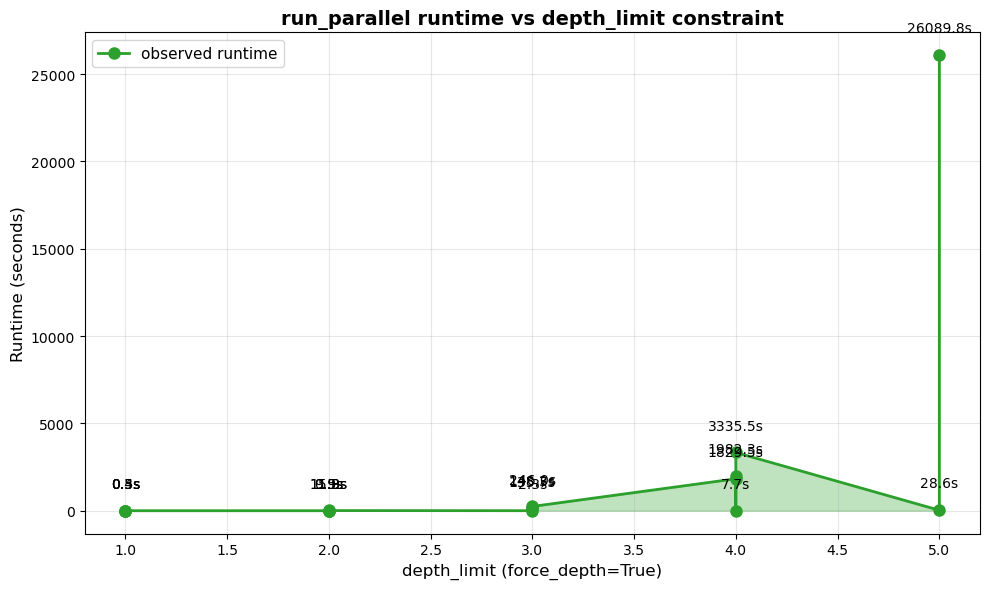

Saved plot to runtime_vs_depth_limit.png


In [27]:
# Plot runtime vs depth_limit (after SLURM jobs complete)
# Load runtimes from SLURM outputs using the existing parse_slurm_output function

def load_depth_test_results_from_slurm(pattern='slurm-*.out'):
    """Load depth test results from SLURM output files.
    
    Parses files matching the pattern and extracts depth_limit and runtime.
    """
    from pathlib import Path
    slurm_files = sorted(Path('.').glob(pattern))
    results = []
    
    for sf in slurm_files:
        parsed = parse_slurm_output(str(sf))
        if not parsed:
            continue
        
        # Extract depth_limit from benchmark_label (format: depth_test_dl{N})
        label = parsed.get('benchmark_label', '')
        if label is None:
            continue
        match = re.search(r'dl(\d+)', label)
        if match:
            depth_limit = int(match.group(1))
            results.append({
                'depth_limit': depth_limit,
                'runtime_seconds': parsed['runtime_seconds'],
                'job_id': parsed['job_id']
            })
    
    return results

if GENERATE_DEPTH_TEST_SCRIPTS and depth_job_scripts:
    print('Attempting to load depth test results from SLURM outputs...')
    depth_results = load_depth_test_results_from_slurm()
    
    if depth_results:
        depth_df = pd.DataFrame(depth_results).sort_values('depth_limit')
        print(f'Loaded {len(depth_df)} completed depth tests:')
        print(depth_df)
        print()
        
        # Plot
        fig, ax = plt.subplots(figsize=(10, 6))
        
        x = depth_df['depth_limit'].values
        y = depth_df['runtime_seconds'].values
        
        ax.plot(x, y, 'o-', linewidth=2, markersize=8, color='tab:green', label='observed runtime')
        ax.fill_between(x, y, alpha=0.3, color='tab:green')
        
        ax.set_xlabel('depth_limit (force_depth=True)', fontsize=12)
        ax.set_ylabel('Runtime (seconds)', fontsize=12)
        ax.set_title('run_parallel runtime vs depth_limit constraint', fontsize=14, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=11)
        
        # Add value labels on points
        for xi, yi in zip(x, y):
            ax.text(xi, yi + max(y)*0.05, f'{yi:.1f}s', ha='center', fontsize=10)
        
        plt.tight_layout()
        plt.savefig('runtime_vs_depth_limit.png', dpi=200)
        plt.show()
        print('Saved plot to runtime_vs_depth_limit.png')
    else:
        print('No completed depth test outputs found yet.')
        print('After running the SLURM jobs, re-run this cell to generate the plot.')
else:
    print('Depth test scripts not yet generated.')
    print('Set GENERATE_DEPTH_TEST_SCRIPTS=True and re-run the previous cell first.')


Loading depth test results organized by molecule...
Loaded results for 4 molecules



Loading depth test results organized by molecule...
Loaded results for 4 molecules



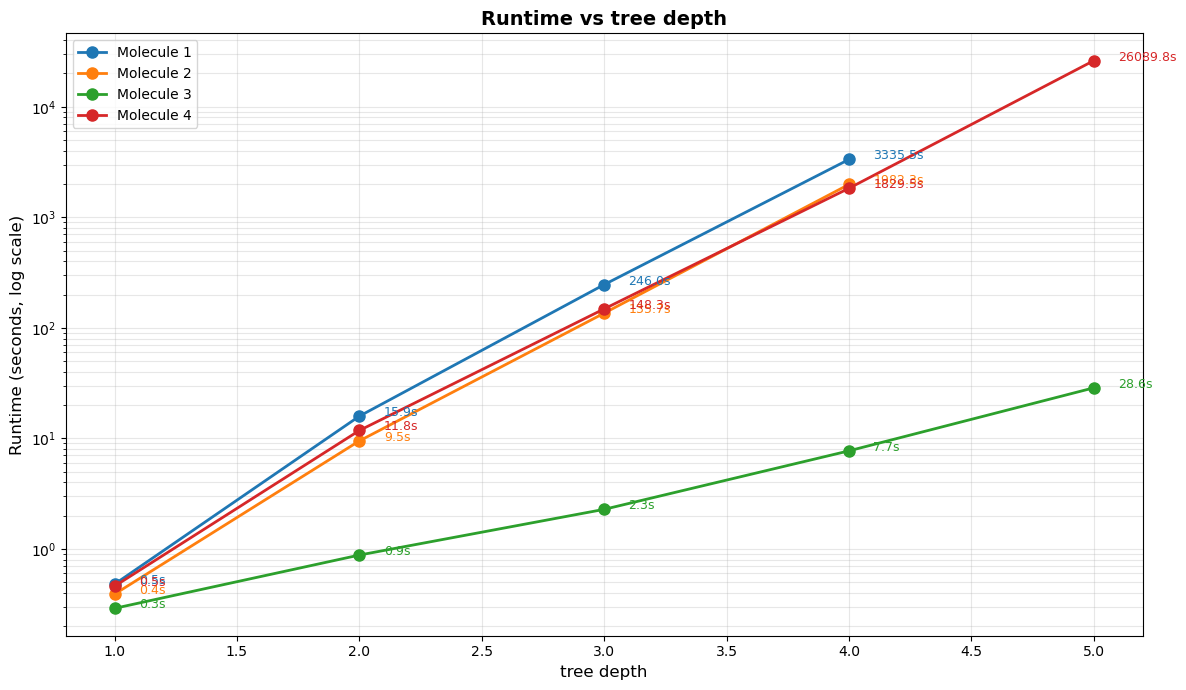

Saved plot to runtime_vs_depth_limit_by_molecule.png


In [31]:
# Plot runtime vs depth_limit with separate lines per molecule (log scale)
# Load runtimes from SLURM outputs and group by molecule

def load_depth_test_results_by_molecule(pattern='slurm-*.out'):
    """Load depth test results from SLURM output files, organized by molecule.
    
    Parses files matching the pattern and extracts depth_limit, runtime, and molecule index.
    Returns dict: {mol_idx: [(depth_limit, runtime), ...]}
    """
    from pathlib import Path
    slurm_files = sorted(Path('.').glob(pattern))
    results_by_mol = {}
    
    for sf in slurm_files:
        parsed = parse_slurm_output(str(sf))
        if not parsed:
            continue
        
        # Extract molecule index and depth_limit from benchmark_label
        # Format: depth_test_mol{i}_dl{N}
        label = parsed.get('benchmark_label', '')
        if label is None:
            continue
        mol_match = re.search(r'mol(\d+)', label)
        depth_match = re.search(r'dl(\d+)', label)
        
        if mol_match and depth_match:
            mol_idx = int(mol_match.group(1))
            depth_limit = int(depth_match.group(1))
            runtime = parsed['runtime_seconds']
            
            if mol_idx not in results_by_mol:
                results_by_mol[mol_idx] = []
            results_by_mol[mol_idx].append((depth_limit, runtime))
    
    # Sort each molecule's results by depth_limit
    for mol_idx in results_by_mol:
        results_by_mol[mol_idx].sort(key=lambda x: x[0])
    
    return results_by_mol

if GENERATE_DEPTH_TEST_SCRIPTS and depth_job_scripts:
    print('Loading depth test results organized by molecule...')
    results_by_mol = load_depth_test_results_by_molecule()
    
    if results_by_mol:
        print(f'Loaded results for {len(results_by_mol)} molecules\n')
        
        # Plot with separate line for each molecule
        fig, ax = plt.subplots(figsize=(12, 7))
        
        colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']
        
        for mol_idx, results in sorted(results_by_mol.items()):
            x = [r[0] for r in results]
            y = [r[1] for r in results]
            
            # Get molecule SMILES for label
            label = f'Molecule {mol_idx + 1}'
            
            color = colors[mol_idx % len(colors)]
            ax.plot(x, y, 'o-', linewidth=2, markersize=8, label=label, color=color)
            
            # Add value labels on points
            for xi, yi in zip(x, y):
                ax.text(xi + 0.1, yi, f'{yi:.1f}s', fontsize=9, color=color)
        
        ax.set_xlabel('tree depth', fontsize=12)
        ax.set_ylabel('Runtime (seconds, log scale)', fontsize=12)
        ax.set_title('Runtime vs tree depth',fontsize=14, fontweight='bold')
        ax.set_yscale('log')
        ax.grid(True, alpha=0.3, which='both')
        ax.legend(fontsize=10, loc='best')
        
        plt.tight_layout()
        plt.savefig('runtime_vs_depth_limit_by_molecule.png', dpi=500)
        plt.show()
        print('Saved plot to runtime_vs_depth_limit_by_molecule.png')
    else:
        print('No completed depth test outputs found yet.')
        print('After running the SLURM jobs, re-run this cell to generate the plot.')
else:
    print('Depth test scripts not yet generated.')
    print('Set GENERATE_DEPTH_TEST_SCRIPTS=True and re-run the script generation cell first.')


In [21]:
# Section 9: Plot 2 - Sources vs Sinks breakdown
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stacked bar: Sources
groups = ['small', 'medium', 'large']
for group in groups:
    mask = df['selection_group'] == group
    group_df = df[mask]
    if not group_df.empty:
        mean_r_src = group_df['reactant_sources'].mean()
        mean_p_src = group_df['product_sources'].mean()
        mean_r_snk = group_df['reactant_sinks'].mean()
        mean_p_snk = group_df['product_sinks'].mean()

ax0 = axes[0]
x_pos = np.arange(len(groups))
r_sources = [df[df['selection_group']==g]['reactant_sources'].mean() for g in groups]
p_sources = [df[df['selection_group']==g]['product_sources'].mean() for g in groups]

ax0.bar(x_pos, r_sources, label='Reactant sources', alpha=0.8, color='tab:blue')
ax0.bar(x_pos, p_sources, bottom=r_sources, label='Product sources', alpha=0.8, color='tab:cyan')
ax0.set_ylabel('Average count', fontsize=11)
ax0.set_xlabel('Reaction group', fontsize=11)
ax0.set_title('Sources: Reactant vs Product', fontsize=12, fontweight='bold')
ax0.set_xticks(x_pos)
ax0.set_xticklabels(groups)
ax0.legend(fontsize=10)
ax0.grid(True, alpha=0.3, axis='y')

# Stacked bar: Sinks
ax1 = axes[1]
r_sinks = [df[df['selection_group']==g]['reactant_sinks'].mean() for g in groups]
p_sinks = [df[df['selection_group']==g]['product_sinks'].mean() for g in groups]

ax1.bar(x_pos, r_sinks, label='Reactant sinks', alpha=0.8, color='tab:red')
ax1.bar(x_pos, p_sinks, bottom=r_sinks, label='Product sinks', alpha=0.8, color='tab:orange')
ax1.set_ylabel('Average count', fontsize=11)
ax1.set_xlabel('Reaction group', fontsize=11)
ax1.set_title('Sinks: Reactant vs Product', fontsize=12, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(groups)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('sources_sinks_breakdown.png', dpi=200)
plt.show()
print('Saved plot to sources_sinks_breakdown.png')

KeyboardInterrupt: 

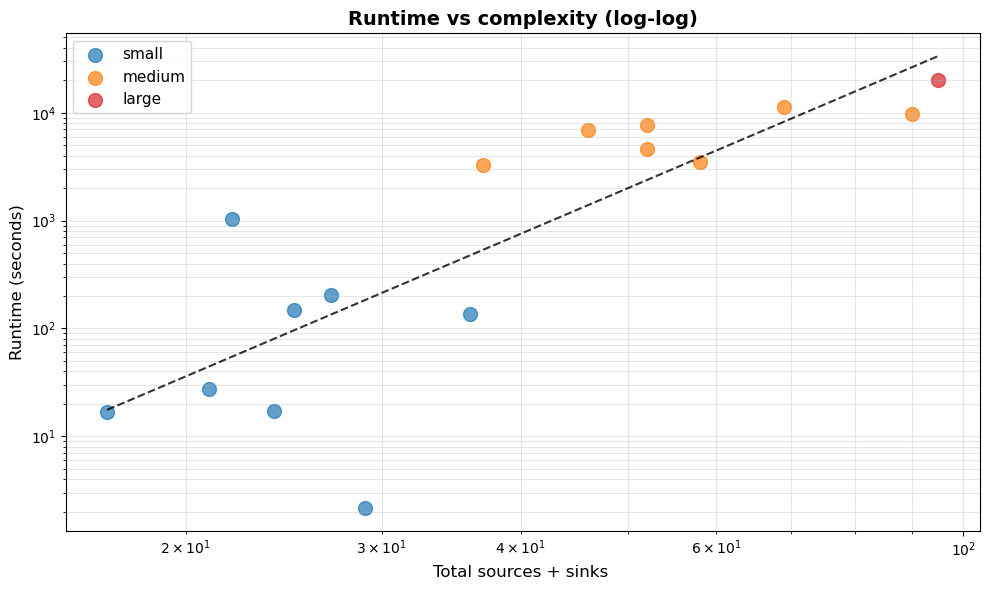

Saved plot to runtime_vs_sources_sinks_loglog.png


In [70]:
# Section 9: Plot 3 - Log-log scatter plot with best-fit power-law line
if not plot_df.empty and (plot_df['runtime_seconds'] > 0).all() and (plot_df['total_sources_sinks'] > 0).all():
    x = plot_df['total_sources_sinks'].values.astype(float)
    y = plot_df['runtime_seconds'].values.astype(float)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for group, color in zip(['small', 'medium', 'large'], ['tab:blue', 'tab:orange', 'tab:red']):
        mask = plot_df['selection_group'] == group
        ax.scatter(x[mask], y[mask], label=group, alpha=0.7, s=100, color=color)
    
    # Best-fit in log-log space (power-law: y = a * x^b)
    if len(x) > 1:
        logx = np.log10(x)
        logy = np.log10(y)
        b, loga = np.polyfit(logx, logy, 1)  # b = slope, loga = intercept
        a = 10 ** loga
        x_fit = np.logspace(np.log10(x.min()), np.log10(x.max()), 200)
        y_fit = a * x_fit ** b
        ax.plot(x_fit, y_fit, 'k--', alpha=0.8)
        #label=f'Power-law fit: y={a:.2e} x^{b:.2f}'
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Total sources + sinks ', fontsize=12)
    ax.set_ylabel('Runtime (seconds)', fontsize=12)
    ax.set_title('Runtime vs complexity (log-log)', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(fontsize=11)
    plt.tight_layout()
    plt.savefig('runtime_vs_sources_sinks_loglog.png', dpi=200)
    plt.show()
    print('Saved plot to runtime_vs_sources_sinks_loglog.png')
else:
    print('Cannot create log-log plot: need positive nonzero x and y values')

/tmp/ipykernel_1535334/3695812428.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_group, labels=['small', 'medium', 'large'], patch_artist=True)


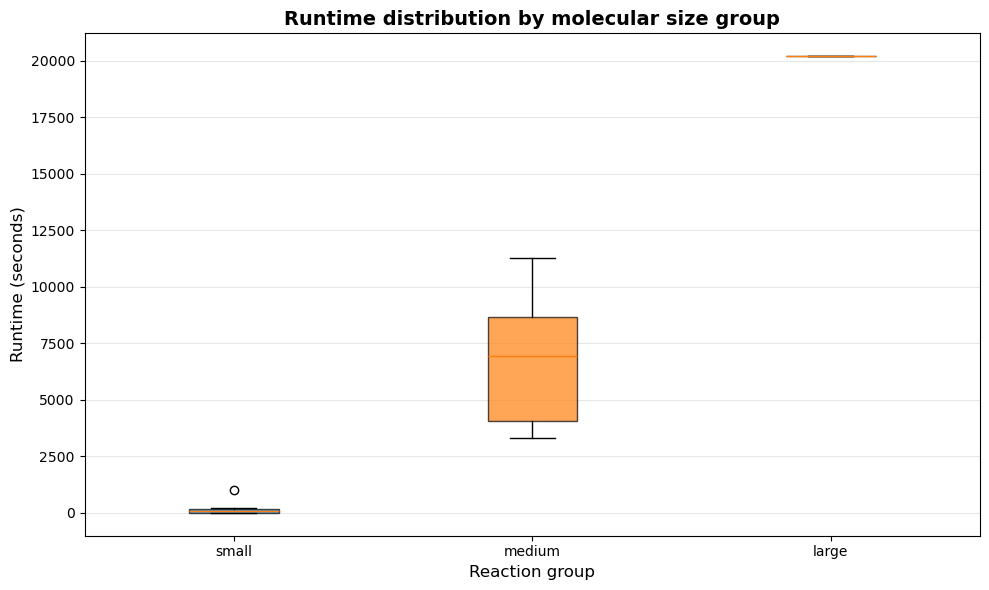

Saved plot to runtime_distribution_by_group.png


In [67]:
# Section 9: Plot 4 - Runtime distribution by group (box plot)
if not plot_df.empty:
    fig, ax = plt.subplots(figsize=(10, 6))
    
    data_by_group = [plot_df[plot_df['selection_group']==g]['runtime_seconds'].dropna().values 
                     for g in ['small', 'medium', 'large']]
    
    bp = ax.boxplot(data_by_group, labels=['small', 'medium', 'large'], patch_artist=True)
    
    colors = ['tab:blue', 'tab:orange', 'tab:red']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax.set_ylabel('Runtime (seconds)', fontsize=12)
    ax.set_xlabel('Reaction group', fontsize=12)
    ax.set_title('Runtime distribution by molecular size group', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.savefig('runtime_distribution_by_group.png', dpi=200)
    plt.show()
    print('Saved plot to runtime_distribution_by_group.png')
else:
    print('Cannot create box plot: no runtime data')

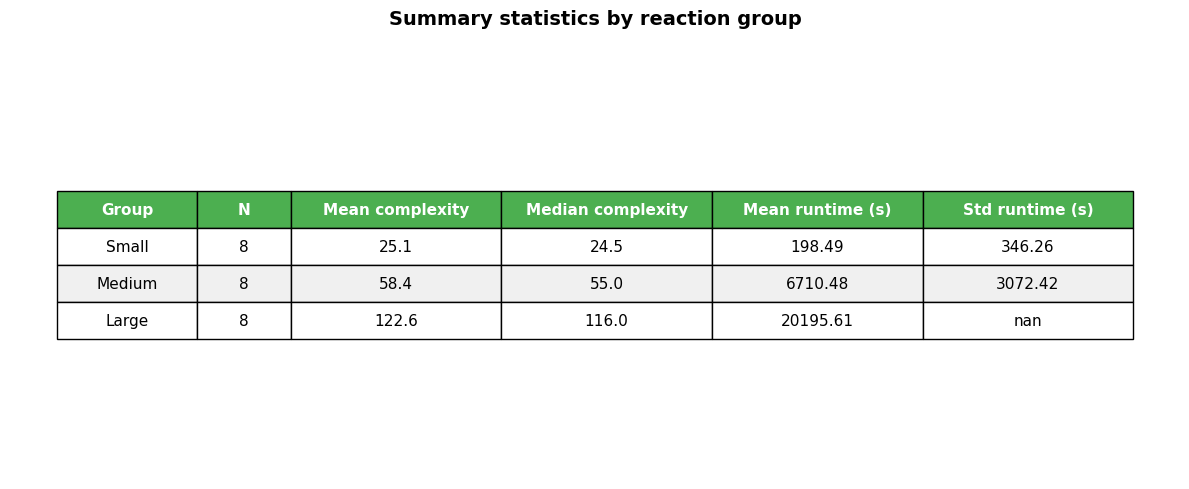

Saved summary table to summary_statistics_table.png


In [68]:
# Section 9: Plot 5 - Summary statistics table as text figure
fig, ax = plt.subplots(figsize=(12, 5))
ax.axis('off')

# Build summary table
summary_data = []
for group in ['small', 'medium', 'large']:
    mask = df['selection_group'] == group
    group_df = df[mask]
    n = len(group_df)
    sources = group_df['total_sources_sinks'].mean()
    sinks = group_df['total_sources_sinks'].median()
    runtimes = group_df[group_df['runtime_seconds'].notna()]['runtime_seconds']
    if len(runtimes) > 0:
        runtime_mean = runtimes.mean()
        runtime_std = runtimes.std()
    else:
        runtime_mean = np.nan
        runtime_std = np.nan
    summary_data.append([group.capitalize(), n, f'{sources:.1f}', f'{sinks:.1f}', 
                         f'{runtime_mean:.2f}', f'{runtime_std:.2f}'])

table = ax.table(cellText=summary_data,
                colLabels=['Group', 'N', 'Mean complexity', 'Median complexity', 'Mean runtime (s)', 'Std runtime (s)'],
                cellLoc='center',
                loc='center',
                colWidths=[0.12, 0.08, 0.18, 0.18, 0.18, 0.18])
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)

# Style header
for i in range(len(summary_data[0])):
    table[(0, i)].set_facecolor('#4CAF50')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Alternate row colors
for i in range(1, len(summary_data) + 1):
    for j in range(len(summary_data[0])):
        if i % 2 == 0:
            table[(i, j)].set_facecolor('#f0f0f0')
        else:
            table[(i, j)].set_facecolor('#ffffff')

plt.title('Summary statistics by reaction group', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('summary_statistics_table.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved summary table to summary_statistics_table.png')

In [ ]:
# Section 10: Simple unit tests / smoke checks
# These do not run run_parallel; only validate counting logic

def test_count_sources_sinks():
    """Test count_sources_sinks on known molecules."""
    # Test 1: ethane should have minimal sources/sinks
    counts_cc = count_sources_sinks('CC')
    assert counts_cc['total_sources'] >= 0, 'Sources should be non-negative'
    assert counts_cc['total_sinks'] >= 0, 'Sinks should be non-negative'
    
    # Test 2: ethanol should have more
    counts_cco = count_sources_sinks('CCO')
    assert counts_cco['total_sources'] >= counts_cc['total_sources'], 'Ethanol should have >= sources than ethane'
    
    print('✓ test_count_sources_sinks passed')

def test_reactions_load():
    """Test that reactions loaded correctly."""
    assert len(all_reactions) > 0, 'Should load at least one reaction'
    row_i, r_smi, p_smi = all_reactions[0]
    r_mol = Chem.MolFromSmiles(r_smi)
    p_mol = Chem.MolFromSmiles(p_smi)
    assert r_mol is not None, f'Reactant SMILES invalid: {r_smi}'
    assert p_mol is not None, f'Product SMILES invalid: {p_smi}'
    print('✓ test_reactions_load passed')

def test_results_df():
    """Test that results DataFrame is valid."""
    assert 'total_sources_sinks' in df.columns, 'Missing total_sources_sinks column'
    assert 'runtime_seconds' in df.columns, 'Missing runtime_seconds column'
    assert 'job_label' in df.columns, 'Missing job_label column'
    assert len(df) > 0, 'Results DataFrame is empty'
    print('✓ test_results_df passed')

# Run tests
test_count_sources_sinks()
test_reactions_load()
test_results_df()
print('\nAll unit tests passed!')

## Final Notes: How to enable and run

### To run locally:
1. Change `RUN_PARALLEL = True` in the setup cell (line ~17)
2. Optionally set `SAMPLE_N` to adjust number of reactions to test
3. Run all cells sequentially. The benchmark loop will time each call.
4. Results are saved to `results_benchmark.csv`
5. Plots are generated automatically (PNG files)

### To generate SLURM job scripts (for cluster submission):
1. Change `RUN_PARALLEL = True` and `RUN_CLUSTER = True`
2. Run cells 1-8. Job scripts will be written to `job_scripts/` directory.
3. Scripts are NOT automatically submitted. To submit:
   ```bash
   sbatch job_scripts/small_row*.sh
   sbatch job_scripts/medium_row*.sh
   sbatch job_scripts/large_row*.sh
   # or individually
   sbatch job_scripts/small_row123.sh
   ```

### To use the template ps.qsub:
- The job scripts are generated with SLURM directives based on `ps.qsub`
- Default: 16 CPUs, 12:50:00 walltime, CLUSTER partition
- Edit `write_job_script()` function to customize (e.g., different partition, CPUs, or walltime)

### Plots generated:
- **runtime_vs_sources_sinks.png** - Scatter plot with best-fit line
- **runtime_vs_sources_sinks_log.png** - Log-scale version for large runtime ranges
- **sources_sinks_breakdown.png** - Stacked bar chart of sources/sinks by group
- **runtime_distribution_by_group.png** - Box plot of runtime distributions
- **summary_statistics_table.png** - Summary statistics table visualization
- **results_benchmark.csv** - Full results DataFrame (for custom analysis)

### Post-processing: Update runtimes from SLURM outputs

After SLURM jobs complete, extract runtimes and update the results DataFrame:

**Automatic matching (recommended):**
```python
df_updated = auto_update_df_from_slurm(df, tolerance=0.95)
df_updated.to_csv(RESULTS_CSV, index=False)
```
This matches target SMILES from `slurm-*.out` files to `product` column using molecular fingerprint similarity.

**Manual matching (if needed):**
```python
# Single file:
df = manual_update_runtime(df, 'small_row1234', 'slurm-14000.out')

# Batch update with mapping:
mapping = {"14000": "small_row1234", "14001": "medium_row5678"}
df = batch_update_runtimes(df, mapping)
```

### Customizing run_parallel parameters:
- A copy of `run_parallel_no_duplicates.py` is provided as `run_parallel_config.py`
- Edit `run_parallel_config.py` to adjust parameters like:
  - `force_depth`, `depth_limit`, `force_correct_last_step`
  - `aromatic`, `follow_on_enabled`
  - Model path (currently `models/v81/xg_model.json`)
- Import from `run_parallel_config` instead of `run_parallel` when needed

### Important:
- The notebook uses `run_parallel` (not `run_parallel_no_duplicates`)
- Original `rules.py` is NOT modified. A local copy `rules_local.py` is used for safety.
- Set `RUN_PARALLEL = False` by default to avoid unintended execution.
- When using cluster mode, verify job scripts before running `sbatch`.
- SLURM parsing skips jobs that didn't complete (no "Total time taken" line).